# Netflix catalogue analysis

**Data:** 8,807 titles on Netflix (movies and TV shows) with type, country, date added, release year, rating, duration and genres. Snapshot up to September 2021.

**Questions**
1. How did the catalogue grow, and how did the movie / TV mix change?
2. Which countries produce the most content?
3. Which genres dominate for movies vs TV?
4. Who is the catalogue aimed at (maturity ratings)?
5. How long are movies and how many seasons do shows run?
6. Is Netflix adding new releases or older back-catalogue titles?

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import style
from common.style import BLUE, ORANGE, AQUA, MUTED

style.apply()
pd.set_option("display.max_columns", 20)
df = pd.read_csv("data/netflix_titles.csv")
print(df.shape)
df.head(3)

(8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...


## 1. Data quality check

In [2]:
quality = pd.DataFrame({"missing": df.isna().sum(), "missing_%": (100 * df.isna().mean()).round(1)})
quality[quality["missing"] > 0]

,missing,missing_%
director,2634,29.9
cast,825,9.4
country,831,9.4
date_added,10,0.1
rating,4,0.0
duration,3,0.0


Three titles have their **duration typed into the `rating` column** (e.g. "74 min"). A real data-entry error: fix it before analysing ratings or durations.

In [3]:
misplaced = df["rating"].str.contains("min", na=False)
display(df.loc[misplaced, ["title", "rating", "duration"]])
df.loc[misplaced, "duration"] = df.loc[misplaced, "rating"]
df.loc[misplaced, "rating"] = np.nan

,title,rating,duration
5541,Louis C.K. 2017,74 min,NaN
5794,Louis C.K.: Hilarious,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,66 min,NaN


## 2. Cleaning and features

In [4]:
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y")
df["year_added"] = df["date_added"].dt.year
df["minutes"] = df["duration"].str.extract(r"(\d+) min").astype(float)
df["seasons"] = df["duration"].str.extract(r"(\d+) Season").astype(float)
df["age_at_add"] = df["year_added"] - df["release_year"]

countries = df.assign(country=df["country"].str.split(", ")).explode("country")
countries["country"] = countries["country"].str.strip().str.rstrip(",")
genres = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre")
print(f"{df['year_added'].isna().sum()} titles without a date added; {countries['country'].nunique()} countries; {genres['genre'].nunique()} genres")

10 titles without a date added; 123 countries; 42 genres


## 3. Catalogue growth: movies vs TV

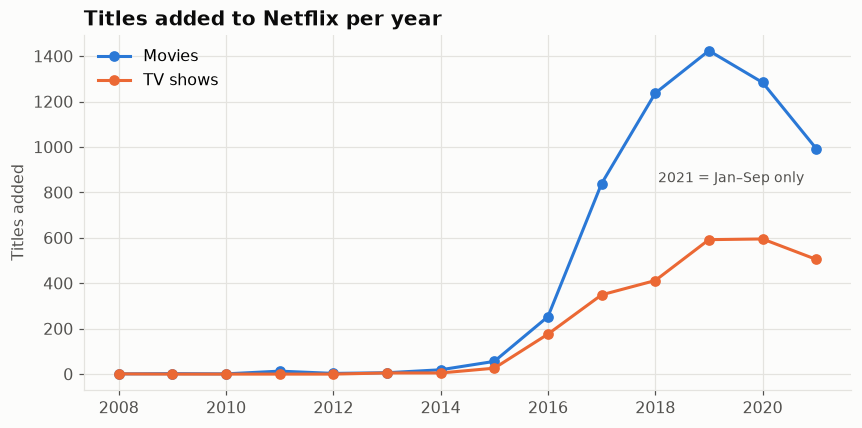

TV shows are 30% of the catalogue. Peak year: 2019 (2,016 titles added).


type,Movie,TV Show
year_added,,
2016.0,253,176
2017.0,839,349
2018.0,1237,412
2019.0,1424,592
2020.0,1284,595
2021.0,993,505


In [5]:
by_year = df.dropna(subset=["year_added"]).query("year_added >= 2008").groupby(["year_added", "type"]).size().unstack(fill_value=0)
share_tv = 100 * df["type"].eq("TV Show").mean()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(by_year.index, by_year["Movie"], "-o", color=BLUE, lw=2, label="Movies")
ax.plot(by_year.index, by_year["TV Show"], "-o", color=ORANGE, lw=2, label="TV shows")
ax.set_title("Titles added to Netflix per year")
ax.set_ylabel("Titles added")
ax.legend(loc="upper left")
ax.annotate("2021 = Jan–Sep only", (2021, by_year.loc[2021, "Movie"]), textcoords="offset points",
            xytext=(-8, -22), ha="right", fontsize=9, color="#52514e")
style.save(fig, "titles_added_per_year")
plt.show()
print(f"TV shows are {share_tv:.0f}% of the catalogue. Peak year: {by_year.sum(axis=1).idxmax():.0f} "
      f"({by_year.sum(axis=1).max():,} titles added).")
by_year.tail(6)

## 4. Where does the content come from?

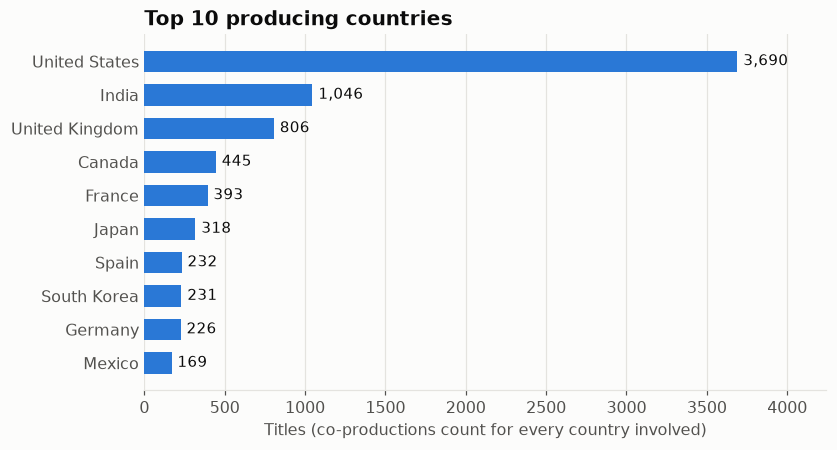

The US is involved in 42% of all titles; India is second with 1,046.


In [6]:
top_countries = countries["country"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(8, 4.2))
style.hbar(ax, top_countries.index, top_countries.values)
ax.set_title("Top 10 producing countries")
ax.set_xlabel("Titles (co-productions count for every country involved)")
style.save(fig, "top_countries")
plt.show()
us_share = 100 * df["country"].str.contains("United States", na=False).mean()
print(f"The US is involved in {us_share:.0f}% of all titles; India is second with {top_countries['India']:,}.")

In [7]:
# India and the US have very different mixes
mix = (countries[countries["country"].isin(top_countries.index[:6])]
       .groupby("country")["type"].value_counts(normalize=True).unstack().mul(100).round(1)
       .sort_values("Movie", ascending=False))
mix

type,Movie,TV Show
country,,
India,92.0,8.0
France,77.1,22.9
United States,74.6,25.4
Canada,71.7,28.3
United Kingdom,66.3,33.7
Japan,37.4,62.6


## 5. Genres: movies vs TV

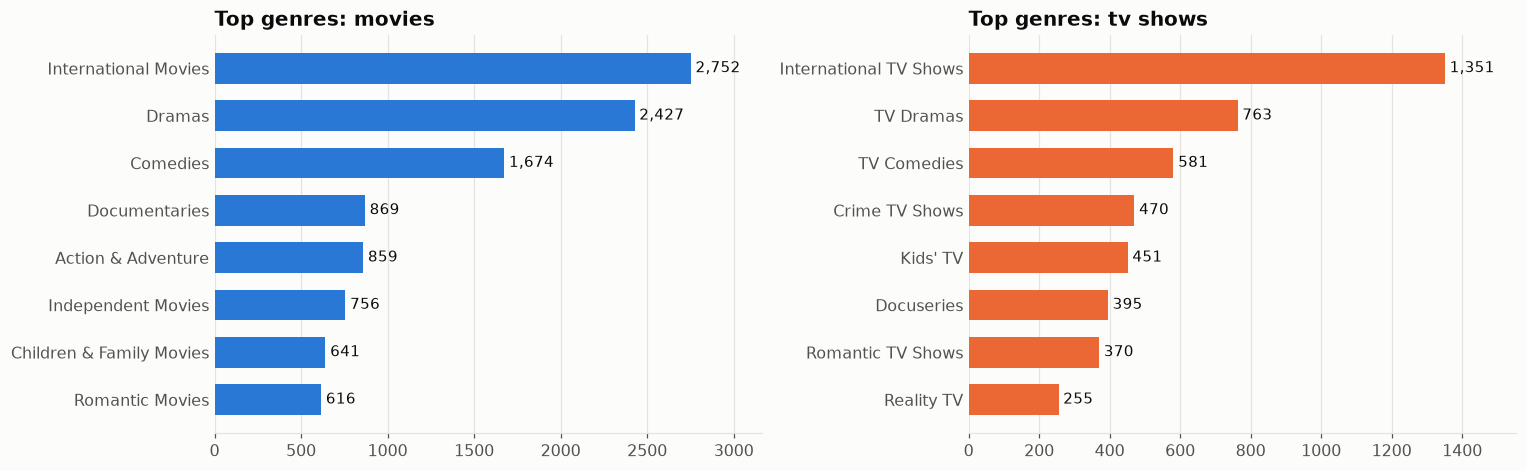

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, kind, color in [(axes[0], "Movie", BLUE), (axes[1], "TV Show", ORANGE)]:
    g = genres[genres["type"] == kind]["genre"].value_counts().head(8)
    style.hbar(ax, g.index, g.values, color=color)
    ax.set_title(f"Top genres: {kind.lower()}s")
fig.tight_layout()
style.save(fig, "top_genres")
plt.show()

## 6. Who is the catalogue for?

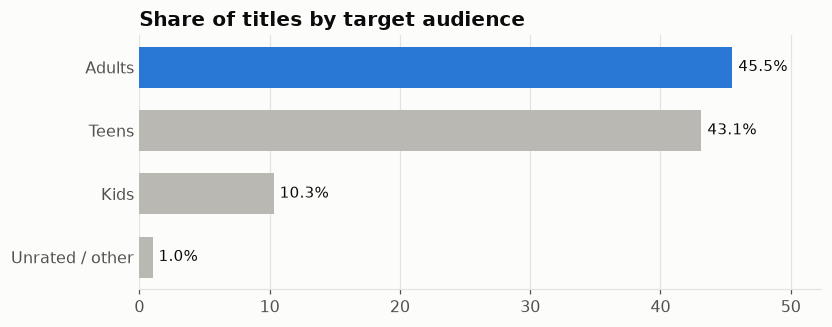

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
Name: count, dtype: int64

In [9]:
rating_groups = {
    "Kids": ["TV-Y", "TV-Y7", "TV-Y7-FV", "G", "TV-G"],
    "Teens": ["PG", "TV-PG", "PG-13", "TV-14"],
    "Adults": ["R", "TV-MA", "NC-17"],
}
lookup = {r: g for g, rs in rating_groups.items() for r in rs}
df["audience"] = df["rating"].map(lookup).fillna("Unrated / other")
aud = df["audience"].value_counts(normalize=True).mul(100).reindex(["Adults", "Teens", "Kids", "Unrated / other"])

fig, ax = plt.subplots(figsize=(8, 3))
style.hbar(ax, aud.index, aud.values, fmt="{:.1f}%", highlight={"Adults"})
ax.set_title("Share of titles by target audience")
style.save(fig, "audience")
plt.show()
df["rating"].value_counts().head(6)

## 7. Length of movies and shows

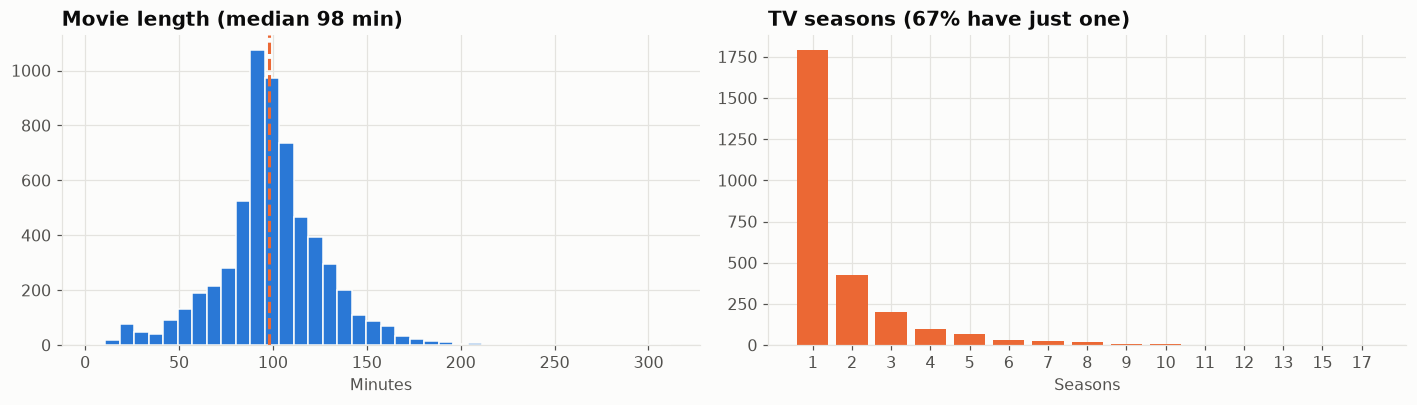

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(df["minutes"].dropna(), bins=40, color=BLUE, edgecolor="#fcfcfb")
axes[0].axvline(df["minutes"].median(), color=ORANGE, ls="--", lw=2)
axes[0].set_title(f"Movie length (median {df['minutes'].median():.0f} min)")
axes[0].set_xlabel("Minutes")
s = df["seasons"].value_counts().sort_index()
axes[1].bar(s.index.astype(int).astype(str), s.values, color=ORANGE)
axes[1].set_title(f"TV seasons ({100 * (df['seasons'] == 1).sum() / df['seasons'].notna().sum():.0f}% have just one)")
axes[1].set_xlabel("Seasons")
fig.tight_layout()
style.save(fig, "durations")
plt.show()

## 8. New releases or back catalogue?

`age_at_add` = year added − release year. A title is *recent* if it arrived on Netflix within a year of its release. Years before 2016 are left out: fewer than 100 titles were added per year, so their percentages are noise.

In [11]:
recent = (df.dropna(subset=["year_added"]).query("year_added >= 2016")
          .assign(recent=lambda d: d["age_at_add"] <= 1)
          .groupby(["year_added", "type"])["recent"].mean().mul(100).round(1).unstack())
recent

type,Movie,TV Show
year_added,,
2016.0,75.5,51.1
2017.0,62.8,52.4
2018.0,49.0,72.3
2019.0,45.9,65.5
2020.0,46.0,75.8
2021.0,40.0,72.1


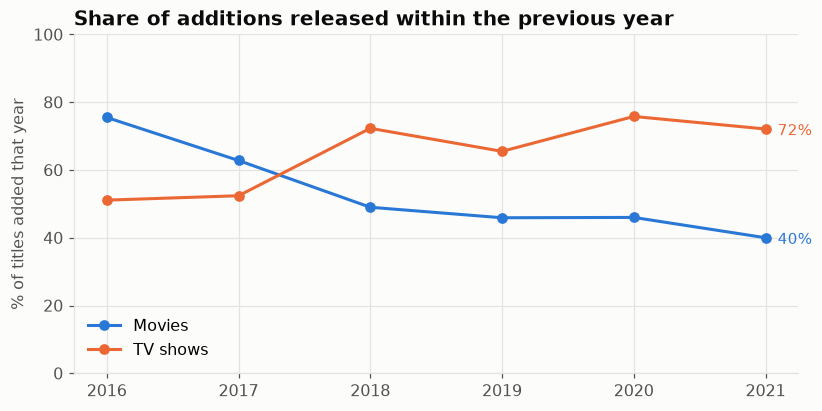

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(recent.index, recent["Movie"], "-o", color=BLUE, lw=2, label="Movies")
ax.plot(recent.index, recent["TV Show"], "-o", color=ORANGE, lw=2, label="TV shows")
for col, color in [("Movie", BLUE), ("TV Show", ORANGE)]:
    ax.annotate(f"{recent[col].iloc[-1]:.0f}%", (recent.index[-1], recent[col].iloc[-1]),
                textcoords="offset points", xytext=(8, -4), color=color, fontsize=10)
ax.set_title("Share of additions released within the previous year")
ax.set_ylabel("% of titles added that year")
ax.set_ylim(0, 100)
ax.legend(loc="lower left")
style.save(fig, "freshness")
plt.show()

## Key findings

Printed from the data above so the summary always matches the analysis:

In [13]:
movies_pct = 100 * df["type"].eq("Movie").mean()
adult_pct = aud["Adults"]
tv_share = 100 * by_year["TV Show"] / by_year.sum(axis=1)
print(f"1. Movies are {movies_pct:.0f}% of the catalogue, but TV's share of new additions has grown since 2018: "
      f"{tv_share.loc[2018]:.0f}% of 2018 additions vs {tv_share.loc[2021]:.0f}% in 2021.")
totals = by_year.sum(axis=1)
print(f"2. Additions peaked in {totals.idxmax():.0f} ({totals.max():,} titles); 2020 fell {100 * (1 - totals.loc[2020] / totals.loc[2019]):.0f}% "
      "(coinciding with COVID-19 production shutdowns).")
print(f"3. The US is involved in {us_share:.0f}% of titles; India ({top_countries['India']:,}) is the clear #2 and is "
      f"{mix.loc['India', 'Movie']:.0f}% movies.")
print(f"4. {adult_pct:.0f}% of titles are rated for adults (R / TV-MA); kids' titles are only {aud['Kids']:.0f}%.")
print(f"5. The median movie runs {df['minutes'].median():.0f} min; "
      f"{100 * (df['seasons'] == 1).sum() / df['seasons'].notna().sum():.0f}% of shows have a single season.")
print(f"6. Two different strategies: {recent.loc[2021, 'TV Show']:.0f}% of TV shows added in 2021 were recent releases, "
      f"but only {recent.loc[2021, 'Movie']:.0f}% of movies (down from {recent.loc[2016, 'Movie']:.0f}% in 2016): "
      "movie additions lean more and more on older titles, while TV additions stay mostly new.")

1. Movies are 70% of the catalogue, but TV's share of new additions has grown since 2018: 25% of 2018 additions vs 34% in 2021.
2. Additions peaked in 2019 (2,016 titles); 2020 fell 7% (coinciding with COVID-19 production shutdowns).
3. The US is involved in 42% of titles; India (1,046) is the clear #2 and is 92% movies.
4. 46% of titles are rated for adults (R / TV-MA); kids' titles are only 10%.
5. The median movie runs 98 min; 67% of shows have a single season.
6. Two different strategies: 72% of TV shows added in 2021 were recent releases, but only 40% of movies (down from 76% in 2016): movie additions lean more and more on older titles, while TV additions stay mostly new.
